**Este notebook tem como objetivo utilizar ferramentas do Python para facilitar cálculos matemáticos e a criação de gráficos. Cada trecho de código será explicado detalhadamente, visando tornar o entendimento mais acessível para o leitor.**

1) No código seguinte é feito a importação das bibliotecas utilizadas e o carregamento do arquivo utilizado.

In [67]:
# Importar bibliotecas necessárias
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, MinMaxScaler
import scipy.stats as stats
from statsmodels.stats.diagnostic import lilliefors

In [68]:
# Carregar os arquivos CSV
df_gw = pd.read_csv("../../data/Grupo com registro entre 07-2024 a 06-2025- GW.csv", sep='\t')

C:\Users\Inteli\AppData\Local\Temp\ipykernel_29956\1456239399.py:2: DtypeWarning: Columns (11,21) have mixed types. Specify dtype option on import or set low_memory=False.
  df_gw = pd.read_csv("../../data/Grupo com registro entre 07-2024 a 06-2025- GW.csv", sep='\t')


2) Na seguinte parte é usado um código para ver as 5 primeiras informações da planilha para auxiliar posteriormente.

In [69]:
df_gw.head() # mostra as primeiras linhas e os nomes de colunas


,id_grupo,id_beneficiario,Numero_do_boleto,data_inclusao,status_boleto,data_vencto,vl_boleto,dt_pagto,vl_pagto,banco,...,pagador_cidade,qtd_acessos_pagador,pagador_dt_ultimo_acesso,pagador_cnpjcpf,pagador_inscricao_hash,valor_abatimento,tipo_juros,juros,tipo_multa,multa
0,212,658,380217446,2024-07-03,BAIXADO,2024-07-29,8528.52,\N,\N,BANCO DO BRASIL,...,Mage,3,2024-08-10 15:58:02,CNPJ,01fa7845e68846b4f804f5df66393cf022c5266cfaf688...,0.0,M,2.84,P,10.00
1,212,658,380217447,2024-07-03,LIQUIDADO,2024-08-27,8528.52,2024-08-23,8528.52,BANCO DO BRASIL,...,Mage,1,2024-08-09 16:35:15,CNPJ,01fa7845e68846b4f804f5df66393cf022c5266cfaf688...,0.0,M,2.84,P,10.00
2,212,658,380217448,2024-07-03,LIQUIDADO,2024-09-26,8528.52,2024-09-23,8528.52,BANCO DO BRASIL,...,Mage,3,2024-09-10 14:30:58,CNPJ,01fa7845e68846b4f804f5df66393cf022c5266cfaf688...,0.0,M,2.84,P,10.00
3,212,658,380217449,2024-07-03,LIQUIDADO,2024-10-28,8528.52,2024-10-24,8528.52,BANCO DO BRASIL,...,Mage,2,2024-09-11 11:54:13,CNPJ,01fa7845e68846b4f804f5df66393cf022c5266cfaf688...,0.0,M,2.84,P,10.00
4,212,658,380217450,2024-07-03,LIQUIDADO,2024-11-25,8528.52,2024-11-26,8528.52,BANCO DO BRASIL,...,Mage,2,2024-09-11 11:55:11,CNPJ,01fa7845e68846b4f804f5df66393cf022c5266cfaf688...,0.0,M,2.84,P,10.00


3) No código seguinte é usado comandos da biblioteca pandas para descobrir a quantidade de valores diferentes de uma dada coluna.

In [70]:

# Mostra valores únicos
print(df_gw['vl_boleto'].nunique())

24106


4) Nos códigos à frente é feito as configurações dos parâmetros como o $\alpha$, também é feito os cálculos para a descoberta do p-valor de cada variável, além de já estar ajustada para as conclusões.

In [71]:
# Configuração
alpha = 0.05  # nível de significância
variaveis = ['vl_boleto', 'vl_pagto', 'juros', 'qtd_acessos_pagador', 'multa']  # ajuste para as colunas do seu dataset


In [72]:
# --- Loop para rodar o teste em cada variável ---
resultados = []

for var in variaveis:
    # Garante que a coluna é numérica e remove valores ausentes
    x = pd.to_numeric(df_gw[var], errors='coerce').dropna()
    
    # Teste de Lilliefors (H0: distribuição é normal com μ e σ estimados)
    stat, p = lilliefors(x, dist='norm')
    
    # Conclusão com base no p-valor
    if p > alpha:
        conclusao = "Não rejeita H₀ (≈ normal)"
    else:
        conclusao = "Rejeita H₀ (não normal)"
    
    resultados.append([var, f"{p:.4f}", conclusao])

In [73]:
# --- Cria tabela organizada ---
tabela = pd.DataFrame(resultados, columns=['Variável', 'p-valor', 'Conclusão'])
print(tabela)

              Variável p-valor                Conclusão
0            vl_boleto  0.0010  Rejeita H₀ (não normal)
1             vl_pagto  0.0010  Rejeita H₀ (não normal)
2                juros  0.0010  Rejeita H₀ (não normal)
3  qtd_acessos_pagador  0.0010  Rejeita H₀ (não normal)
4                multa  0.0010  Rejeita H₀ (não normal)


5) No código seguinte é feito a limpeza dos dados, permitindo que não existam falhas em códigos que usem essas variáaveis.

In [74]:
for var in variaveis:
    # Limpeza
    df_gw[var] = (
        df_gw[var]
        .astype(str)
        .str.replace(',', '.', regex=False)
        .str.replace('[^0-9.]', '', regex=True)
    )
    
    # Substitui strings vazias por NaN
    df_gw[var] = df_gw[var].replace('', np.nan)
    
    # Converte para float
    df_gw[var] = df_gw[var].astype(float)
    
    print(f"{var} convertida para float. Valores únicos: {df_gw[var].nunique()}")


vl_boleto convertida para float. Valores únicos: 24106
vl_pagto convertida para float. Valores únicos: 22689
juros convertida para float. Valores únicos: 2079
qtd_acessos_pagador convertida para float. Valores únicos: 48
multa convertida para float. Valores únicos: 959


6) No código seguinte é plotado o histograma referente a cada variável, além do cálculo de suas médias e medianas.

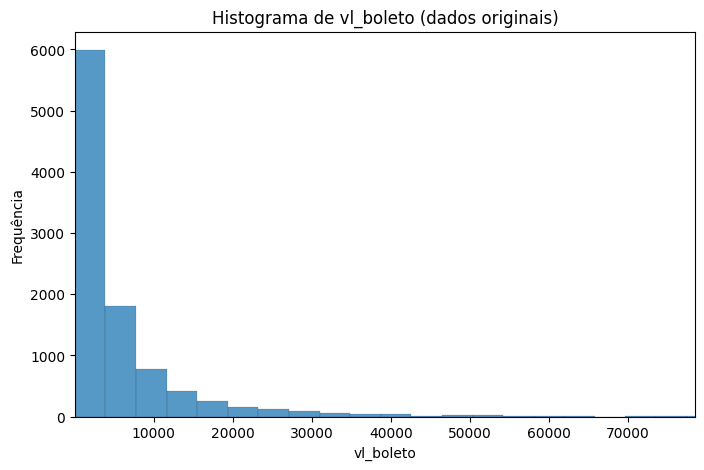

Variável: vl_boleto
Média: 8278.10, Mediana: 2799.24
Comentário: O histograma mostra a concentração da maioria dos valores em uma faixa estreita,
com alguns valores isolados muito maiores. Isso é consistente com os resultados do teste de normalidade.



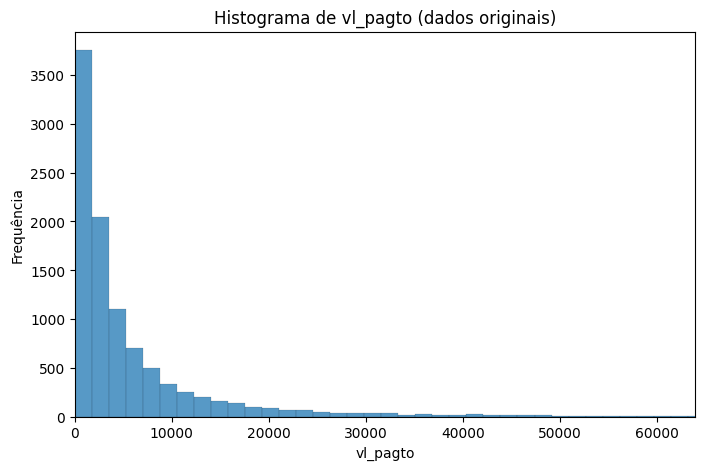

Variável: vl_pagto
Média: 7302.77, Mediana: 2708.33
Comentário: O histograma mostra a concentração da maioria dos valores em uma faixa estreita,
com alguns valores isolados muito maiores. Isso é consistente com os resultados do teste de normalidade.



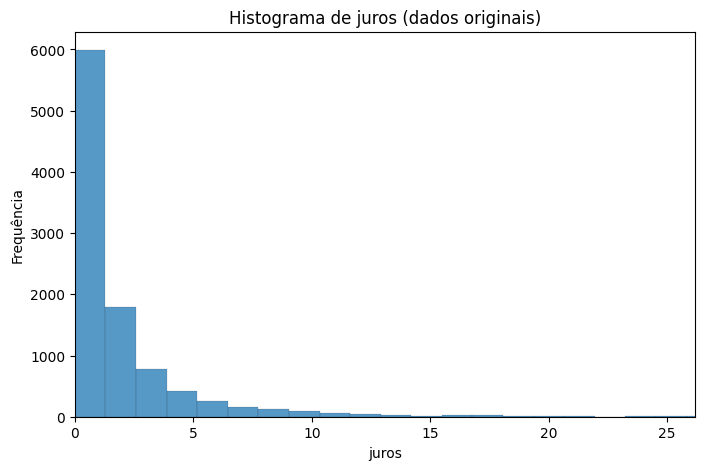

Variável: juros
Média: 2.76, Mediana: 0.94
Comentário: O histograma mostra a concentração da maioria dos valores em uma faixa estreita,
com alguns valores isolados muito maiores. Isso é consistente com os resultados do teste de normalidade.



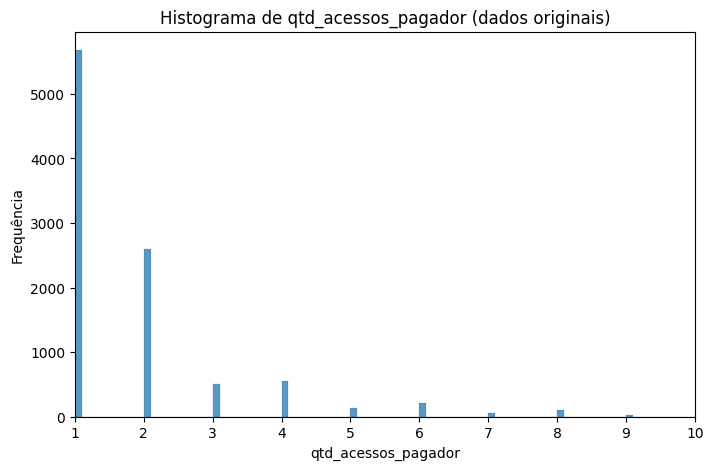

Variável: qtd_acessos_pagador
Média: 1.98, Mediana: 1.00
Comentário: O histograma mostra a concentração da maioria dos valores em uma faixa estreita,
com alguns valores isolados muito maiores. Isso é consistente com os resultados do teste de normalidade.



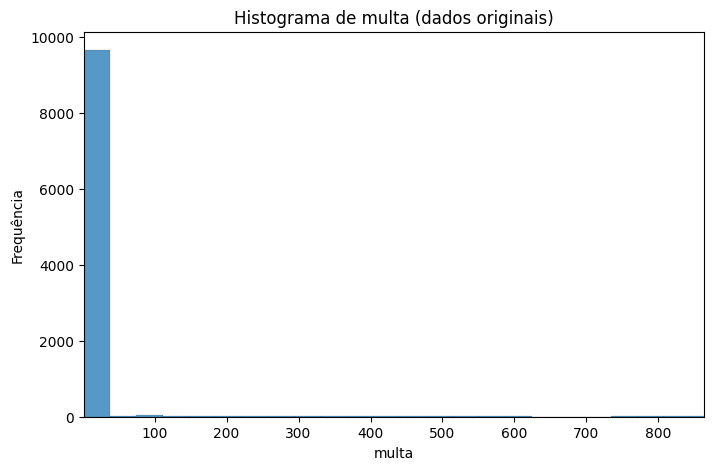

Variável: multa
Média: 44.54, Mediana: 10.00
Comentário: O histograma mostra a concentração da maioria dos valores em uma faixa estreita,
com alguns valores isolados muito maiores. Isso é consistente com os resultados do teste de normalidade.



In [75]:
max_plot = 10000

for var in variaveis:
    x_full = df_gw[var].dropna()
    
    # Subamostra se necessário
    x = x_full if x_full.size <= max_plot else x_full.sample(max_plot, random_state=42)
    
    plt.figure(figsize=(8,5))
    sns.histplot(x, bins=500, kde=False)
    
    # Ajuste opcional do eixo x para valores concentrados
    plt.xlim(x.min(), x.quantile(0.99))  # mostra até 99% dos dados
    
    plt.title(f'Histograma de {var} (dados originais)')
    plt.xlabel(var)
    plt.ylabel('Frequência')
    plt.show()
    
    # Média e mediana
    media = x_full.mean()
    mediana = x_full.median()
    print(f"Variável: {var}")
    print(f"Média: {media:.2f}, Mediana: {mediana:.2f}")
    print("Comentário: O histograma mostra a concentração da maioria dos valores em uma faixa estreita,")
    print("com alguns valores isolados muito maiores. Isso é consistente com os resultados do teste de normalidade.\n")

7) O código a frente faz o cálculo dos dados estatísticos das variáveis escolhidas.

In [76]:
estatisticas = []

for var in variaveis:
    x = pd.to_numeric(df_gw[var], errors='coerce').dropna()
    estatisticas.append({
        "Variável": var,
        "Mínimo": x.min(),
        "Máximo": x.max(),
        "Média": x.mean(),
        "Mediana": x.median(),
        "Desvio padrão (populacional)": x.std(ddof=0)
    })

df_estatisticas = pd.DataFrame(estatisticas)
print(df_estatisticas)


              Variável  Mínimo      Máximo        Média  Mediana  \
0            vl_boleto    0.05  3325737.15  8278.098431  2799.24   
1             vl_pagto    0.00  1936467.04  7302.765326  2708.33   
2                juros    0.00     1108.58     2.763921     0.94   
3  qtd_acessos_pagador    1.00       86.00     1.975555     1.00   
4                multa    1.46    18325.01    44.540882    10.00   

   Desvio padrão (populacional)  
0                  46433.895360  
1                  30500.663670  
2                     15.480987  
3                      2.196959  
4                    326.982654  


8) O cógio a frente é responsável por criar os histográmas com os dados já escalonados.

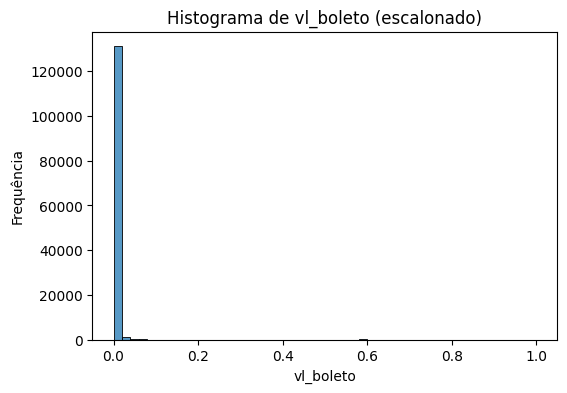

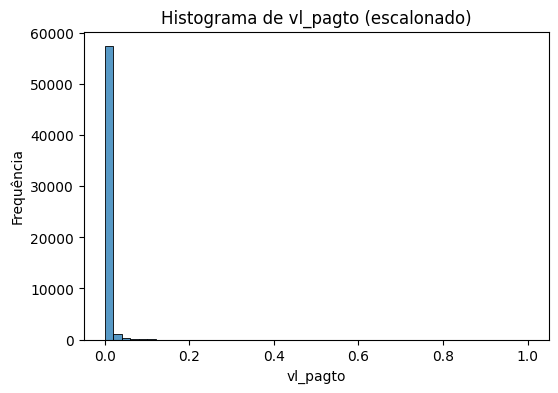

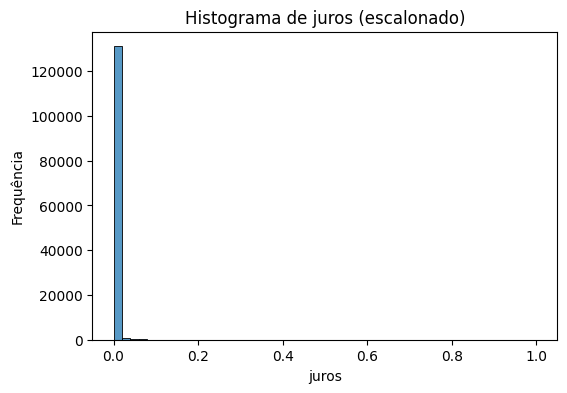

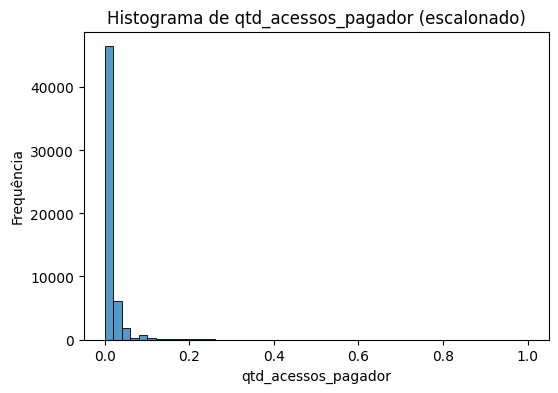

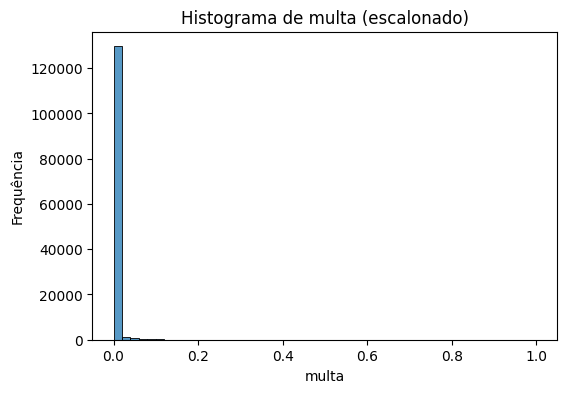

In [77]:
# Criar cópia antes do escalonamento
df_gw_orig = df_gw.copy()

# Criar escalonadores
scaler_minmax = MinMaxScaler()
scaler_std = StandardScaler()

# Normalização
df_gw[['vl_boleto', 'vl_pagto', 'qtd_acessos_pagador']] = scaler_minmax.fit_transform(df_gw[['vl_boleto', 'vl_pagto', 'qtd_acessos_pagador']])

# Padronização
df_gw[['juros', 'multa']] = scaler_minmax.fit_transform(df_gw[['juros', 'multa']])

# Plot histogramas dos dados escalonados
for var in variaveis:
    plt.figure(figsize=(6,4))
    sns.histplot(df_gw[var], bins=50, kde=False)
    plt.title(f'Histograma de {var} (escalonado)')
    plt.xlabel(var)
    plt.ylabel('Frequência')
    plt.show()


9) O código seguinte é responsável por apresentar os 10 primeiros dados de todas as variáveis escolhidas, antes e depois do escalonamento.

In [78]:
# 10 primeiros registros originais
print("10 primeiros registros (originais):")
display(df_gw_orig[variaveis].head(10))

# 10 primeiros registros escalonados
print("10 primeiros registros (escalonados):")
display(df_gw[variaveis].head(10))

10 primeiros registros (originais):


,vl_boleto,vl_pagto,juros,qtd_acessos_pagador,multa
0,8528.52,NaN,2.84,3.0,10.0
1,8528.52,8528.52,2.84,1.0,10.0
2,8528.52,8528.52,2.84,3.0,10.0
3,8528.52,8528.52,2.84,2.0,10.0
4,8528.52,8528.52,2.84,2.0,10.0
5,8528.49,8528.49,2.84,2.0,10.0
6,726.97,726.97,0.24,1.0,10.0
7,726.97,726.97,0.24,1.0,10.0
8,726.97,NaN,0.24,2.0,10.0
9,726.97,726.97,0.24,2.0,10.0


10 primeiros registros (escalonados):


,vl_boleto,vl_pagto,juros,qtd_acessos_pagador,multa
0,0.002564,NaN,0.002562,0.023529,0.000466
1,0.002564,0.004404,0.002562,0.000000,0.000466
2,0.002564,0.004404,0.002562,0.023529,0.000466
3,0.002564,0.004404,0.002562,0.011765,0.000466
4,0.002564,0.004404,0.002562,0.011765,0.000466
5,0.002564,0.004404,0.002562,0.011765,0.000466
6,0.000219,0.000375,0.000216,0.000000,0.000466
7,0.000219,0.000375,0.000216,0.000000,0.000466
8,0.000219,NaN,0.000216,0.011765,0.000466
9,0.000219,0.000375,0.000216,0.011765,0.000466
